# 04 — Baseline Model Implementation

## Project
Incremental Slimming–Fattening Ensemble for Imbalanced Classification (ISFE)

## Objective
To establish baseline performance on the Credit Card Fraud Detection dataset using:

1. Decision Tree
2. Random Forest
3. Support Vector Machine (SVM)
4. Simple Ensemble Classifier

## Evaluation Metrics
- Macro-F1 Score
- Balanced Accuracy
- Minority-Class Recall
- Precision
- Confusion Matrix

The training partition is used for model fitting, the validation
partition for model comparison, and the test partition is reserved
for final evaluation.

In [2]:
# Cell 2 — Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

import joblib
import time
import warnings

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
PROJECT_DIR = Path("..")

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"
FIGURE_DIR = PROJECT_DIR / "figures"
REPORT_DIR = PROJECT_DIR / "reports"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directories configured.")
print("Processed data:", PROCESSED_DIR.resolve())

Project directories configured.
Processed data: /Users/jasmithav/isfe_creditcard_project/data/processed


In [5]:
X_train = pd.read_csv(PROCESSED_DIR / "X_train.csv")
X_val = pd.read_csv(PROCESSED_DIR / "X_val.csv")

y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv")["Class"]
y_val = pd.read_csv(PROCESSED_DIR / "y_val.csv")["Class"]

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

Training data: (182276, 30)
Validation data: (45570, 30)

Training class distribution:
Class
0    181961
1       315
Name: count, dtype: int64

Validation class distribution:
Class
0    45491
1       79
Name: count, dtype: int64


In [6]:
assert X_train.shape == (182276, 30)
assert X_val.shape == (45570, 30)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)

assert X_train.isnull().sum().sum() == 0
assert X_val.isnull().sum().sum() == 0

assert set(y_train.unique()) == {0, 1}
assert set(y_val.unique()) == {0, 1}

print("All baseline data integrity checks passed.")

All baseline data integrity checks passed.


In [7]:
# Cell 6 — Define baseline classifiers

models = {
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Linear SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LinearSVC(
            class_weight="balanced",
            random_state=RANDOM_STATE,
            max_iter=5000,
            dual="auto"
        ))
    ])
}

# Hard voting combines the predicted class labels.
models["Voting Ensemble"] = VotingClassifier(
    estimators=[
        ("dt", models["Decision Tree"]),
        ("rf", models["Random Forest"]),
        ("svm", models["Linear SVM"])
    ],
    voting="hard",
    n_jobs=-1
)

print("Baseline models configured:")
for name in models:
    print("-", name)

Baseline models configured:
- Decision Tree
- Random Forest
- Linear SVM
- Voting Ensemble


In [8]:
# Cell 7 — Train baseline classifiers

trained_models = {}
training_times = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    start_time = time.time()

    model.fit(X_train, y_train)

    elapsed_time = time.time() - start_time

    trained_models[name] = model
    training_times[name] = elapsed_time

    print(f"{name} trained successfully.")
    print(f"Training time: {elapsed_time:.2f} seconds")

print("\nAll baseline models trained.")


Training Decision Tree...
Decision Tree trained successfully.
Training time: 6.68 seconds

Training Random Forest...
Random Forest trained successfully.
Training time: 47.55 seconds

Training Linear SVM...
Linear SVM trained successfully.
Training time: 1.13 seconds

Training Voting Ensemble...
Voting Ensemble trained successfully.
Training time: 48.21 seconds

All baseline models trained.


In [9]:
# Cell 8 — Predict on validation data

validation_predictions = {}

for name, model in trained_models.items():

    print(f"Predicting with {name}...")

    predictions = model.predict(X_val)

    validation_predictions[name] = predictions

print("\nValidation predictions generated.")

Predicting with Decision Tree...
Predicting with Random Forest...
Predicting with Linear SVM...
Predicting with Voting Ensemble...

Validation predictions generated.


In [10]:
# Cell 9 — Evaluate baseline models

results = []

for name, predictions in validation_predictions.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "Fraud Precision": precision_score(
            y_val, predictions,
            pos_label=1,
            zero_division=0
        ),
        "Fraud Recall": recall_score(
            y_val, predictions,
            pos_label=1,
            zero_division=0
        ),
        "Fraud F1": f1_score(
            y_val, predictions,
            pos_label=1,
            zero_division=0
        ),
        "Training Time (s)": training_times[name]
    })

baseline_results = pd.DataFrame(results)

baseline_results = baseline_results.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

display(baseline_results.round(4))

,Model,Accuracy,Macro F1,Balanced Accuracy,Fraud Precision,Fraud Recall,Fraud F1,Training Time (s)
0,Random Forest,0.9996,0.9361,0.9113,0.9286,0.8228,0.8725,47.5477
1,Voting Ensemble,0.9995,0.9294,0.9239,0.8701,0.8481,0.8590,48.2051
2,Decision Tree,0.9992,0.8795,0.8795,0.7595,0.7595,0.7595,6.6837
3,Linear SVM,0.9768,0.5554,0.9568,0.0656,0.9367,0.1226,1.1330


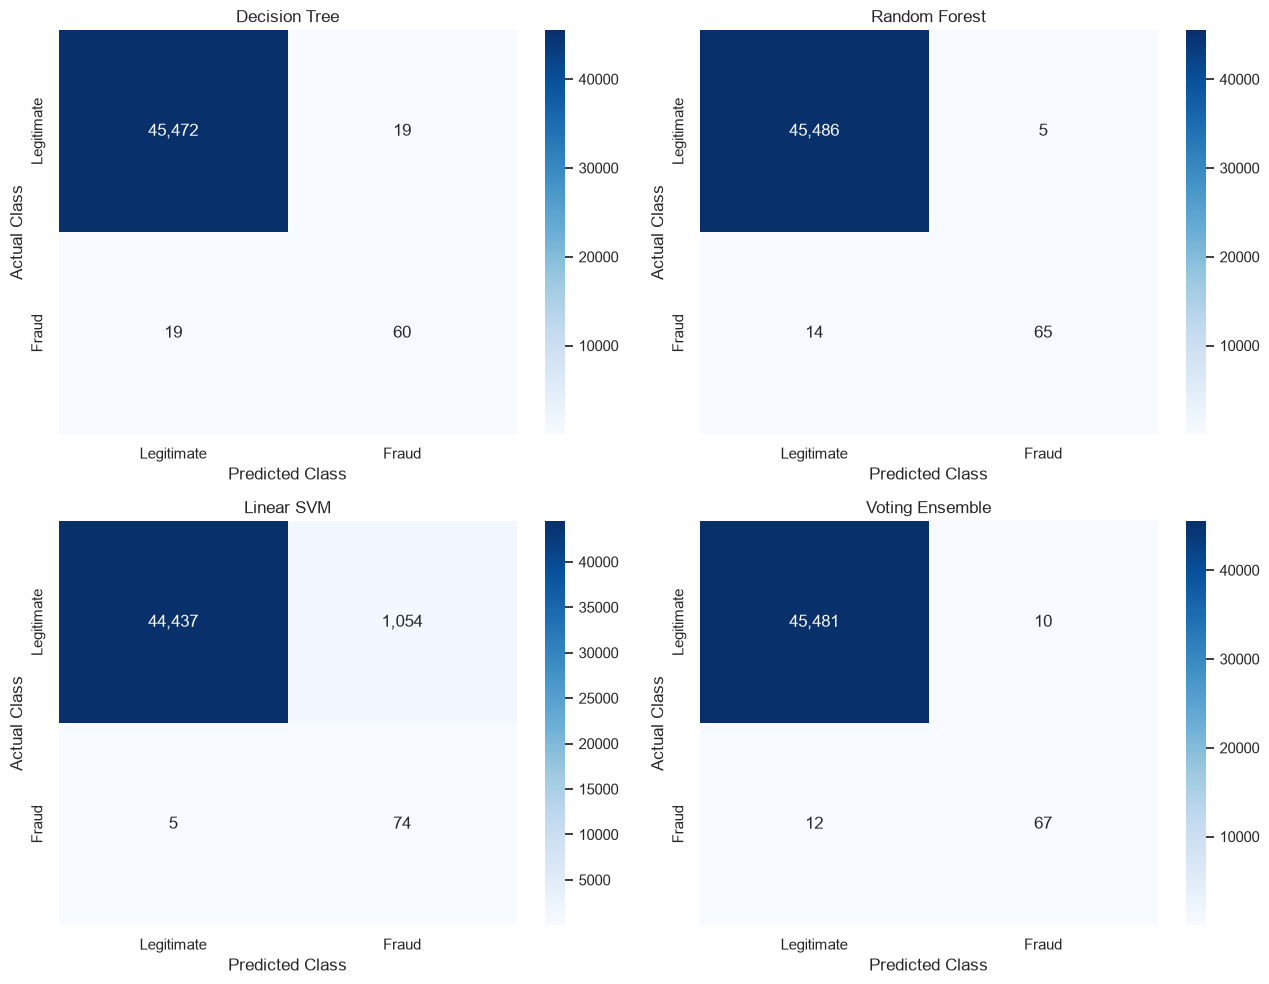

In [11]:
# Cell 10 — Generate confusion matrices

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, (name, predictions) in zip(
    axes.flatten(),
    validation_predictions.items()
):
    cm = confusion_matrix(y_val, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt=",",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "baseline_confusion_matrices.png", dpi=300)
plt.show()

In [12]:
# Cell 11 — Classification reports

for name, predictions in validation_predictions.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_val,
            predictions,
            target_names=["Legitimate", "Fraud"],
            digits=4,
            zero_division=0
        )
    )


Decision Tree
              precision    recall  f1-score   support

  Legitimate     0.9996    0.9996    0.9996     45491
       Fraud     0.7595    0.7595    0.7595        79

    accuracy                         0.9992     45570
   macro avg     0.8795    0.8795    0.8795     45570
weighted avg     0.9992    0.9992    0.9992     45570


Random Forest
              precision    recall  f1-score   support

  Legitimate     0.9997    0.9999    0.9998     45491
       Fraud     0.9286    0.8228    0.8725        79

    accuracy                         0.9996     45570
   macro avg     0.9641    0.9113    0.9361     45570
weighted avg     0.9996    0.9996    0.9996     45570


Linear SVM
              precision    recall  f1-score   support

  Legitimate     0.9999    0.9768    0.9882     45491
       Fraud     0.0656    0.9367    0.1226        79

    accuracy                         0.9768     45570
   macro avg     0.5327    0.9568    0.5554     45570
weighted avg     0.9983    0.976

In [13]:
# Cell 12 — Save baseline experiment outputs

baseline_results.to_csv(
    REPORT_DIR / "baseline_results.csv",
    index=False
)

for name, model in trained_models.items():

    filename = name.lower().replace(" ", "_") + ".joblib"

    joblib.dump(
        model,
        MODEL_DIR / filename
    )

print("Baseline results saved.")
print("Trained models saved.")

Baseline results saved.
Trained models saved.


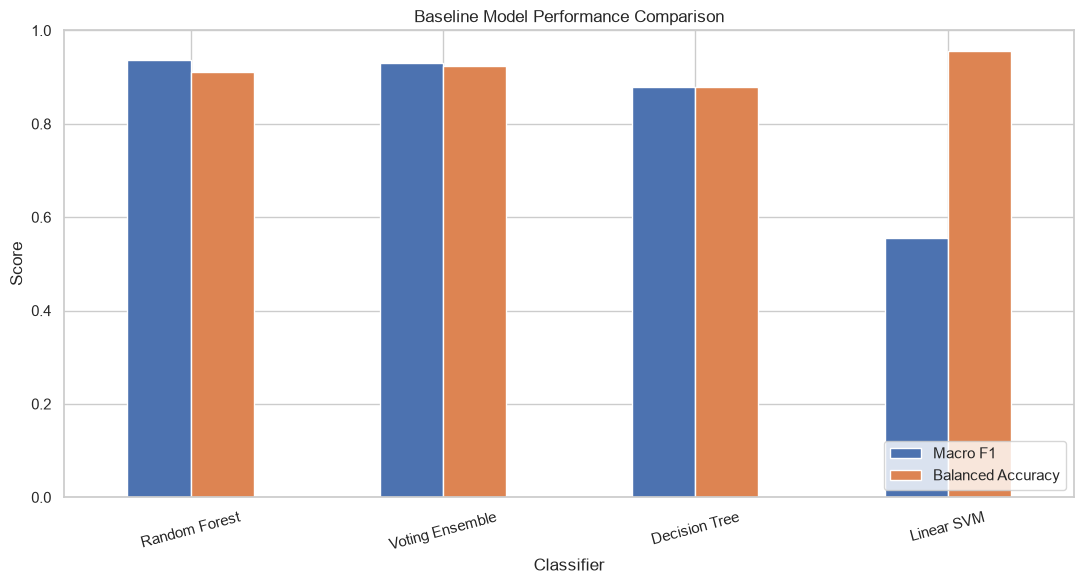

In [14]:
# Cell 13 — Compare Macro-F1 and balanced accuracy

comparison = baseline_results.set_index("Model")[
    ["Macro F1", "Balanced Accuracy"]
]

comparison.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    rot=15
)

plt.title("Baseline Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Classifier")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "baseline_model_comparison.png",
    dpi=300
)

plt.show()

## Baseline Experimental Findings

The baseline classifiers demonstrate different performance
characteristics on the highly imbalanced credit card fraud dataset.

Random Forest achieved the highest Macro-F1 score of 0.9361
and fraud precision of 0.9286. It correctly identified 65
out of 79 fraudulent transactions while producing only
5 false positives.

The Voting Ensemble achieved a fraud recall of 0.8481
and balanced accuracy of 0.9239.

Linear SVM achieved the highest fraud recall of 0.9367,
but its fraud precision was only 0.0656, indicating a
large number of false-positive predictions.

Decision Tree provided a simpler baseline, with a
Macro-F1 score of 0.8795.

These findings establish the baseline against which the
proposed ISFE approach will be evaluated.